# Asg 2: VGG16 (Simple) vs VGG16 (Transfer Learning) on Food-11

This notebook implements two experiments on the Food-11 dataset (same data pipeline as the AlexNet / GoogleNet assignment):

1. **VGG16 – Simple**: the VGG16 architecture trained **from scratch** (random weights, no pretraining).
2. **VGG16 – Transfer Learning**: VGG16 with **ImageNet pretrained weights**, trained in two phases:
   - Phase 1: convolutional base frozen, only the new classifier head is trained
   - Phase 2: fine-tuning – the last convolutional block (`block5`) is unfrozen and trained with a very small learning rate

For both experiments the notebook produces: training / validation accuracy and loss graphs, test accuracy, confusion matrices for the **training, validation and test** sets (counts + normalized), classification report, and a final side-by-side comparison.

> **Kaggle setup:** turn on a **GPU** (Settings → Accelerator) and **Internet** (Settings → Internet → On). Internet is needed only to download the ImageNet VGG16 weights for transfer learning.

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from tensorflow.keras import layers, models, regularizers
from tensorflow.keras.applications import VGG16
from tensorflow.keras.applications.vgg16 import preprocess_input
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
from sklearn.metrics import confusion_matrix, classification_report

# Reproducibility
SEED = 42
np.random.seed(SEED)
tf.random.set_seed(SEED)

print("TensorFlow version:", tf.__version__)
print("GPU available:", tf.config.list_physical_devices("GPU"))

TensorFlow version: 2.20.0
GPU available: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU'), PhysicalDevice(name='/physical_device:GPU:1', device_type='GPU')]


In [2]:
DATASET_PATH = "/kaggle/input/datasets/trolukovich/food11-image-dataset"
# If the path above does not exist on your Kaggle notebook, try:
# DATASET_PATH = "/kaggle/input/food11-image-dataset"
TRAIN_PATH = os.path.join(DATASET_PATH, "training")
VALIDATION_PATH = os.path.join(DATASET_PATH, "validation")
TEST_PATH = os.path.join(DATASET_PATH, "evaluation")

# ---------------- Hyperparameters ----------------
IMG_SIZE = (160, 160)
BATCH_SIZE = 32
NUM_CLASSES = 11
SEED = 42

# VGG16 simple (from scratch)
EPOCHS_SIMPLE = 30
LR_SIMPLE = 1e-4
INIT = "he_normal"

# VGG16 transfer learning
EPOCHS_TL_HEAD = 10        # phase 1: frozen base
EPOCHS_TL_FINE = 15        # phase 2: fine-tune block5
LR_TL_HEAD = 1e-3
LR_TL_FINE = 1e-5
# -------------------------------------------------

class_names = sorted([
    folder for folder in os.listdir(TRAIN_PATH)
    if os.path.isdir(os.path.join(TRAIN_PATH, folder))
])

print("Classes:", class_names)
print("Number of classes:", len(class_names))

Classes: ['Bread', 'Dairy product', 'Dessert', 'Egg', 'Fried food', 'Meat', 'Noodles-Pasta', 'Rice', 'Seafood', 'Soup', 'Vegetable-Fruit']
Number of classes: 11


## Preprocessing and Data Augmentation

* **Simple VGG16** uses pixel rescaling (`1/255`), same as the previous assignment.
* **Transfer-learning VGG16** must use `vgg16.preprocess_input` (the same preprocessing the ImageNet weights were trained with: BGR + mean subtraction), otherwise the pretrained features work poorly.

Augmentation is applied to training images only. Validation and test images are only preprocessed. Test/validation generators use `shuffle=False` so predictions line up with labels in the confusion matrix.

In [3]:
AUG = dict(
    rotation_range=15,
    width_shift_range=0.1,
    height_shift_range=0.1,
    zoom_range=0.1,
    shear_range=0.05,
    horizontal_flip=True,
)

def make_generators(preprocess=None, rescale=None):
    kw = {}
    if preprocess is not None:
        kw["preprocessing_function"] = preprocess
    if rescale is not None:
        kw["rescale"] = rescale

    train_gen = ImageDataGenerator(**kw, **AUG)
    eval_gen = ImageDataGenerator(**kw)

    train = train_gen.flow_from_directory(
        TRAIN_PATH, target_size=IMG_SIZE, batch_size=BATCH_SIZE,
        class_mode="categorical", shuffle=True, seed=SEED)
    val = eval_gen.flow_from_directory(
        VALIDATION_PATH, target_size=IMG_SIZE, batch_size=BATCH_SIZE,
        class_mode="categorical", shuffle=False)
    test = eval_gen.flow_from_directory(
        TEST_PATH, target_size=IMG_SIZE, batch_size=BATCH_SIZE,
        class_mode="categorical", shuffle=False)
    return train, val, test

# Generators for the simple (from scratch) model
train_simple, val_simple, test_simple = make_generators(rescale=1.0/255)

# Generators for the transfer-learning model
train_tl, val_tl, test_tl = make_generators(preprocess=preprocess_input)

# Training data WITHOUT augmentation and WITHOUT shuffling - used only to build the
# training confusion matrix (labels must line up with predictions)
def make_train_eval(preprocess=None, rescale=None):
    kw = {}
    if preprocess is not None:
        kw["preprocessing_function"] = preprocess
    if rescale is not None:
        kw["rescale"] = rescale
    return ImageDataGenerator(**kw).flow_from_directory(
        TRAIN_PATH, target_size=IMG_SIZE, batch_size=BATCH_SIZE,
        class_mode="categorical", shuffle=False)

train_eval_simple = make_train_eval(rescale=1.0/255)
train_eval_tl = make_train_eval(preprocess=preprocess_input)

print("Training:", train_simple.samples)
print("Validation:", val_simple.samples)
print("Test:", test_simple.samples)

Found 9866 images belonging to 11 classes.
Found 3430 images belonging to 11 classes.
Found 3347 images belonging to 11 classes.
Found 9866 images belonging to 11 classes.
Found 3430 images belonging to 11 classes.
Found 3347 images belonging to 11 classes.
Found 9866 images belonging to 11 classes.
Found 9866 images belonging to 11 classes.
Training: 9866
Validation: 3430
Test: 3347


## Helper functions (graphs + confusion matrix)

In [4]:
def plot_history(history_dict, title, phase_split=None):
    """Training vs validation accuracy and loss. phase_split = epoch index where fine-tuning starts."""
    for metric, name in [("accuracy", "Accuracy"), ("loss", "Loss")]:
        plt.figure(figsize=(8, 5))
        plt.plot(history_dict[metric], label=f"Training {name}")
        plt.plot(history_dict["val_" + metric], label=f"Validation {name}")
        if phase_split is not None:
            plt.axvline(phase_split - 0.5, color="gray", linestyle="--", label="Start of fine-tuning")
        plt.title(f"{title} - {name}")
        plt.xlabel("Epoch")
        plt.ylabel(name)
        plt.legend()
        plt.grid(True)
        plt.show()


def evaluate_with_confusion(model, generator, title):
    generator.reset()
    probs = model.predict(generator, verbose=1)
    y_pred = np.argmax(probs, axis=1)
    y_true = generator.classes
    labels = list(generator.class_indices.keys())

    cm = confusion_matrix(y_true, y_pred)
    cm_norm = cm.astype("float") / cm.sum(axis=1, keepdims=True)

    fig, axes = plt.subplots(1, 2, figsize=(20, 8))
    for ax, data, fmt, sub in [(axes[0], cm, "d", "Counts"),
                               (axes[1], cm_norm, ".2f", "Normalized (row %)")]:
        im = ax.imshow(data, cmap="Blues")
        ax.set_title(f"{title}\nConfusion Matrix - {sub}")
        ax.set_xlabel("Predicted label")
        ax.set_ylabel("True label")
        ax.set_xticks(range(len(labels)))
        ax.set_yticks(range(len(labels)))
        ax.set_xticklabels(labels, rotation=45, ha="right")
        ax.set_yticklabels(labels)
        thresh = data.max() / 2.0
        for i in range(data.shape[0]):
            for j in range(data.shape[1]):
                ax.text(j, i, format(data[i, j], fmt), ha="center", va="center", fontsize=8,
                        color="white" if data[i, j] > thresh else "black")
        fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
    plt.tight_layout()
    plt.show()

    print(f"Classification Report - {title}")
    print(classification_report(y_true, y_pred, target_names=labels, digits=3))
    return cm, y_true, y_pred

# Experiment 1 — VGG16 Simple (trained from scratch)

The standard VGG16 layout: 5 blocks of 3×3 convolutions (2-2-3-3-3 conv layers) with max pooling, followed by a fully connected classifier. All weights are randomly initialised (He normal) – no pretraining. The classifier uses Dense(1024) layers (instead of 4096) to keep the model smaller for the 160×160 input and Kaggle GPU memory. Only early stopping / LR scheduling are used so training does not run forever on a plateau.

In [5]:
def conv_block(x, filters, n_convs):
    for _ in range(n_convs):
        x = layers.Conv2D(filters, (3, 3), padding="same", activation="relu",
                          kernel_initializer=INIT)(x)
    return layers.MaxPooling2D((2, 2), strides=2)(x)


def build_vgg16_simple():
    inp = layers.Input(shape=(*IMG_SIZE, 3))
    x = conv_block(inp, 64, 2)
    x = conv_block(x, 128, 2)
    x = conv_block(x, 256, 3)
    x = conv_block(x, 512, 3)
    x = conv_block(x, 512, 3)
    x = layers.Flatten()(x)
    x = layers.Dense(1024, activation="relu", kernel_initializer=INIT)(x)
    x = layers.Dense(1024, activation="relu", kernel_initializer=INIT)(x)
    out = layers.Dense(NUM_CLASSES, activation="softmax")(x)
    return models.Model(inp, out, name="VGG16_Simple")


vgg_simple = build_vgg16_simple()
vgg_simple.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=LR_SIMPLE),
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)
vgg_simple.summary()

I0000 00:00:1795157142.206374      24 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13756 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1795157142.210618      24 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13756 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


Model: "VGG16_Simple"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 160, 160, 64)   │         1,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 160, 160, 64)   │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 80, 80, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 80, 80, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 80, 80, 128)    │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 40, 40, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 40, 40, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 40, 40, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_6 (Conv2D)               │ (None, 40, 40, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 20, 20, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_7 (Conv2D)               │ (None, 20, 20, 512)    │     1,180,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_8 (Conv2D)               │ (None, 20, 20, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_9 (Conv2D)               │ (None, 20, 20, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 10, 10, 512)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_10 (Conv2D)              │ (None, 10, 10, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_11 (Conv2D)              │ (None, 10, 10, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_12 (Conv2D)              │ (None, 10, 10, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 5, 5, 512)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 12800)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1024)           │    13,108,224 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1024)           │     1,049,600 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 11)             │        11,275 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 28,883,787 (110.18 MB)

 Trainable params: 28,883,787 (110.18 MB)

 Non-trainable params: 0 (0.00 B)

In [6]:
early_stopping_simple = EarlyStopping(monitor="val_loss", patience=8,
                                      restore_best_weights=True, verbose=1)
reduce_lr_simple = ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=3,
                                     min_lr=1e-6, verbose=1)

history_simple = vgg_simple.fit(
    train_simple,
    epochs=EPOCHS_SIMPLE,
    validation_data=val_simple,
    callbacks=[early_stopping_simple, reduce_lr_simple]
)

Epoch 1/30


2026-11-20 06:46:08.027708: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-11-20 06:46:08.226081: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-11-20 06:46:09.353953: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-11-20 06:46:09.527540: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-11-20 06:46:11.685460: E external/local_xla/xla/stream_

176/309 ━━━━━━━━━━━━━━━━━━━━ 4:20 2s/step - accuracy: 0.1540 - loss: 2.4819

2026-11-20 06:52:13.339810: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-11-20 06:52:13.533484: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-11-20 06:52:13.981901: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-11-20 06:52:14.149943: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-11-20 06:52:15.172804: E external/local_xla/xla/stream_

309/309 ━━━━━━━━━━━━━━━━━━━━ 799s 2s/step - accuracy: 0.2093 - loss: 2.2180 - val_accuracy: 0.2583 - val_loss: 2.1128 - learning_rate: 1.0000e-04
Epoch 2/30
309/309 ━━━━━━━━━━━━━━━━━━━━ 111s 360ms/step - accuracy: 0.3068 - loss: 1.9658 - val_accuracy: 0.3192 - val_loss: 2.0121 - learning_rate: 1.0000e-04
Epoch 3/30
309/309 ━━━━━━━━━━━━━━━━━━━━ 110s 356ms/step - accuracy: 0.3798 - loss: 1.8063 - val_accuracy: 0.3808 - val_loss: 1.8472 - learning_rate: 1.0000e-04
Epoch 4/30
309/309 ━━━━━━━━━━━━━━━━━━━━ 110s 355ms/step - accuracy: 0.4194 - loss: 1.6746 - val_accuracy: 0.4577 - val_loss: 1.6862 - learning_rate: 1.0000e-04
Epoch 5/30
309/309 ━━━━━━━━━━━━━━━━━━━━ 111s 360ms/step - accuracy: 0.4621 - loss: 1.5543 - val_accuracy: 0.4510 - val_loss: 1.5990 - learning_rate: 1.0000e-04
Epoch 6/30
309/309 ━━━━━━━━━━━━━━━━━━━━ 111s 359ms/step - accuracy: 0.4944 - loss: 1.4625 - val_accuracy: 0.4688 - val_loss: 1.6153 - learning_rate: 1.0000e-04
Epoch 7/30
309/309 ━━━━━━━━━━━━━━━━━━━━ 111s 358ms/ste

105/105 ━━━━━━━━━━━━━━━━━━━━ 123s 1s/step - accuracy: 0.6603 - loss: 1.0166
VGG16 Simple - Test Loss: 1.0166
VGG16 Simple - Test Accuracy: 66.03%


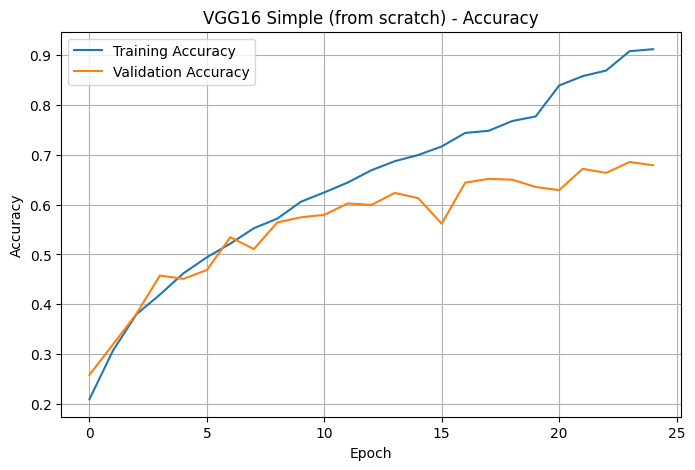

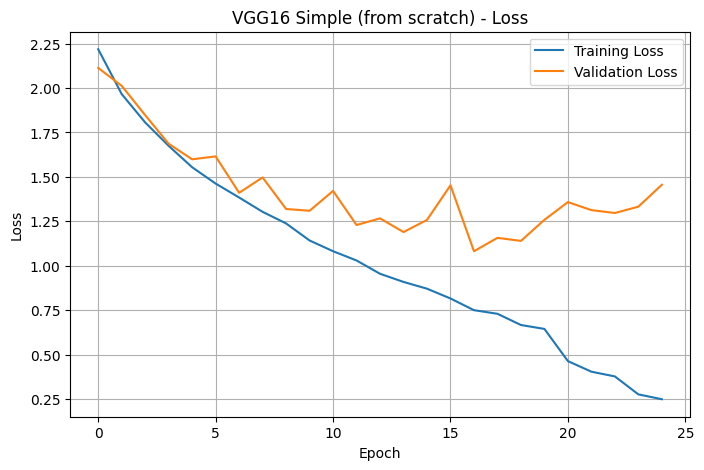

In [7]:
simple_test_loss, simple_test_acc = vgg_simple.evaluate(test_simple, verbose=1)
print(f"VGG16 Simple - Test Loss: {simple_test_loss:.4f}")
print(f"VGG16 Simple - Test Accuracy: {simple_test_acc*100:.2f}%")

plot_history(history_simple.history, "VGG16 Simple (from scratch)")

309/309 ━━━━━━━━━━━━━━━━━━━━ 44s 140ms/step


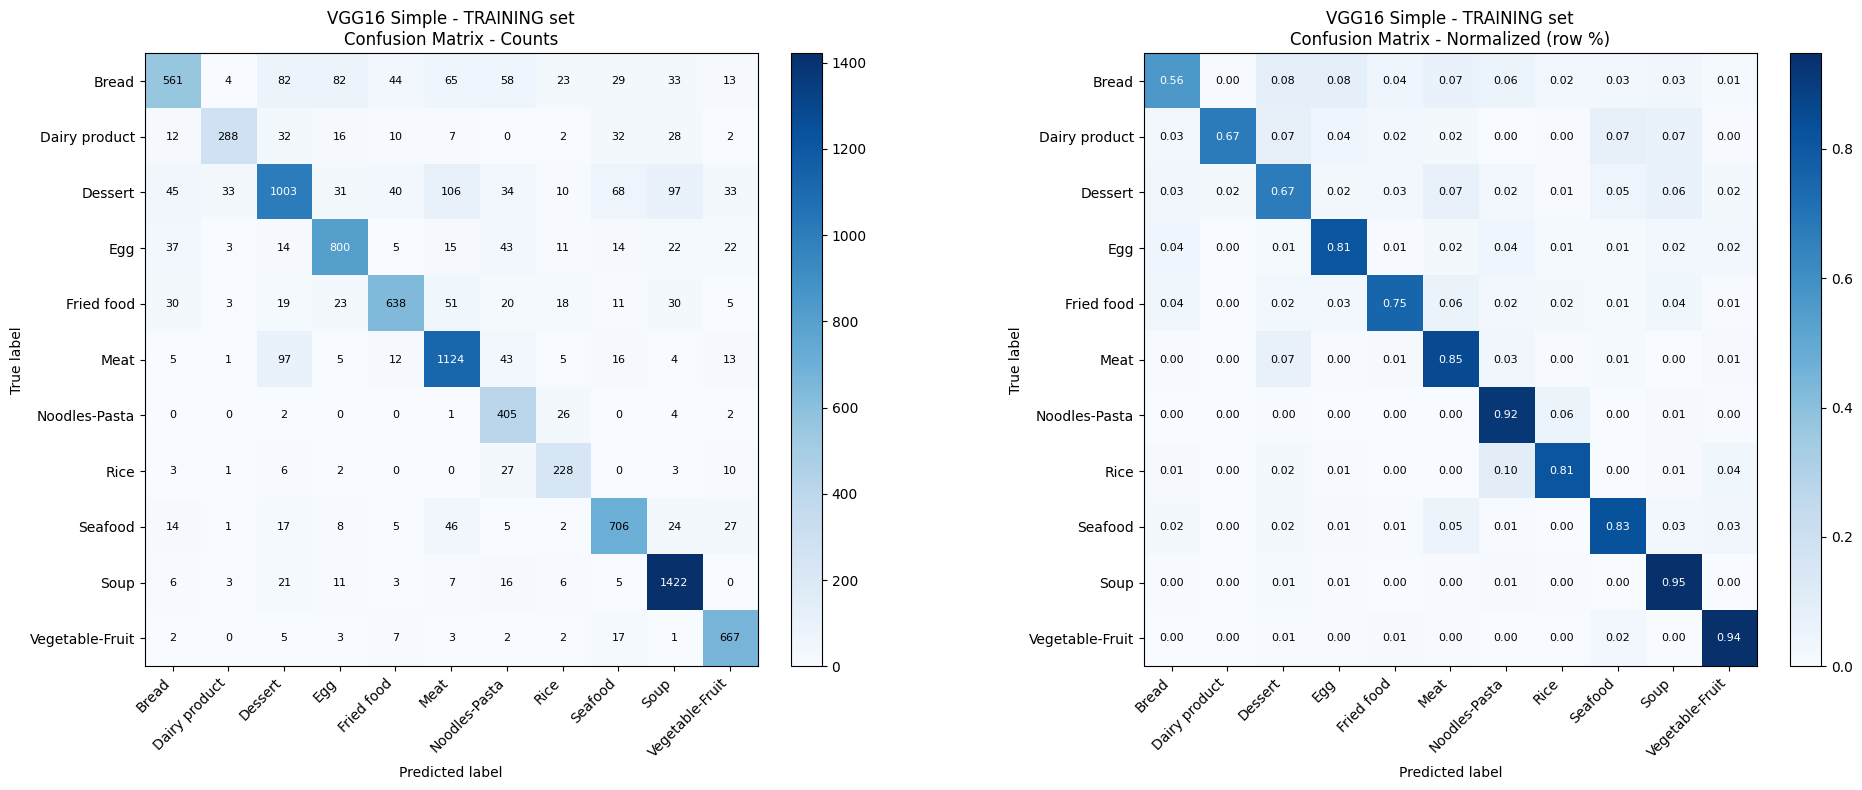

Classification Report - VGG16 Simple - TRAINING set
                 precision    recall  f1-score   support

          Bread      0.785     0.564     0.657       994
  Dairy product      0.855     0.671     0.752       429
        Dessert      0.773     0.669     0.717      1500
            Egg      0.815     0.811     0.813       986
     Fried food      0.835     0.752     0.792       848
           Meat      0.789     0.848     0.817      1325
  Noodles-Pasta      0.620     0.920     0.741       440
           Rice      0.685     0.814     0.744       280
        Seafood      0.786     0.826     0.805       855
           Soup      0.853     0.948     0.898      1500
Vegetable-Fruit      0.840     0.941     0.888       709

       accuracy                          0.795      9866
      macro avg      0.785     0.797     0.784      9866
   weighted avg      0.798     0.795     0.791      9866

108/108 ━━━━━━━━━━━━━━━━━━━━ 15s 135ms/step


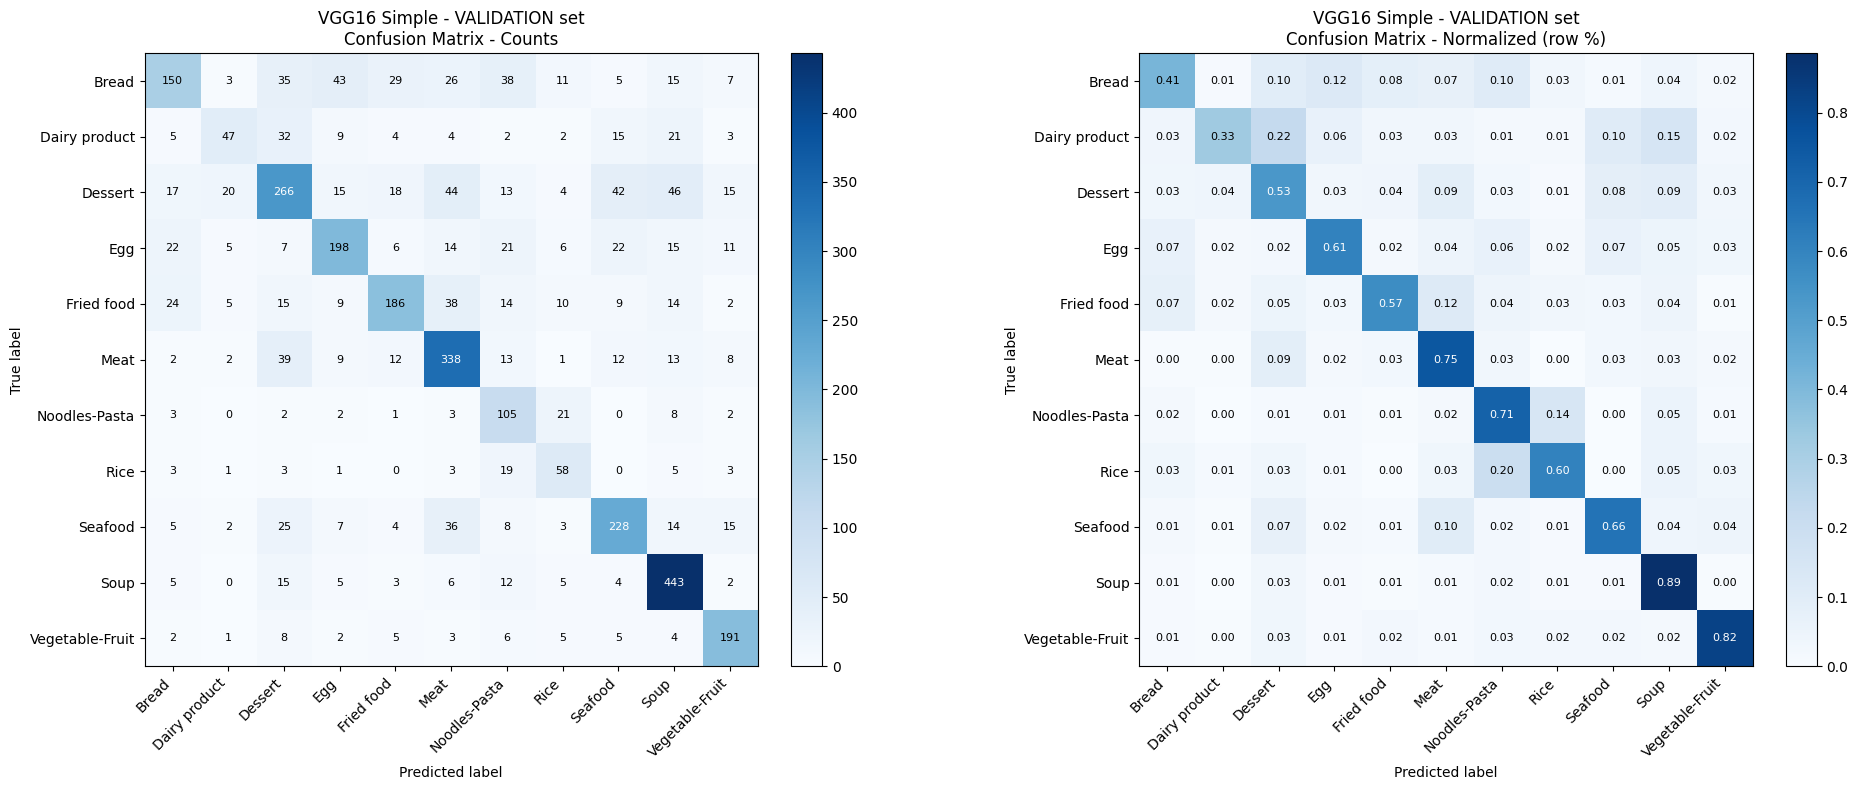

Classification Report - VGG16 Simple - VALIDATION set
                 precision    recall  f1-score   support

          Bread      0.630     0.414     0.500       362
  Dairy product      0.547     0.326     0.409       144
        Dessert      0.595     0.532     0.562       500
            Egg      0.660     0.606     0.632       327
     Fried food      0.694     0.571     0.626       326
           Meat      0.656     0.753     0.701       449
  Noodles-Pasta      0.418     0.714     0.528       147
           Rice      0.460     0.604     0.523        96
        Seafood      0.667     0.657     0.662       347
           Soup      0.741     0.886     0.807       500
Vegetable-Fruit      0.737     0.823     0.778       232

       accuracy                          0.644      3430
      macro avg      0.619     0.626     0.611      3430
   weighted avg      0.647     0.644     0.638      3430

105/105 ━━━━━━━━━━━━━━━━━━━━ 14s 131ms/step


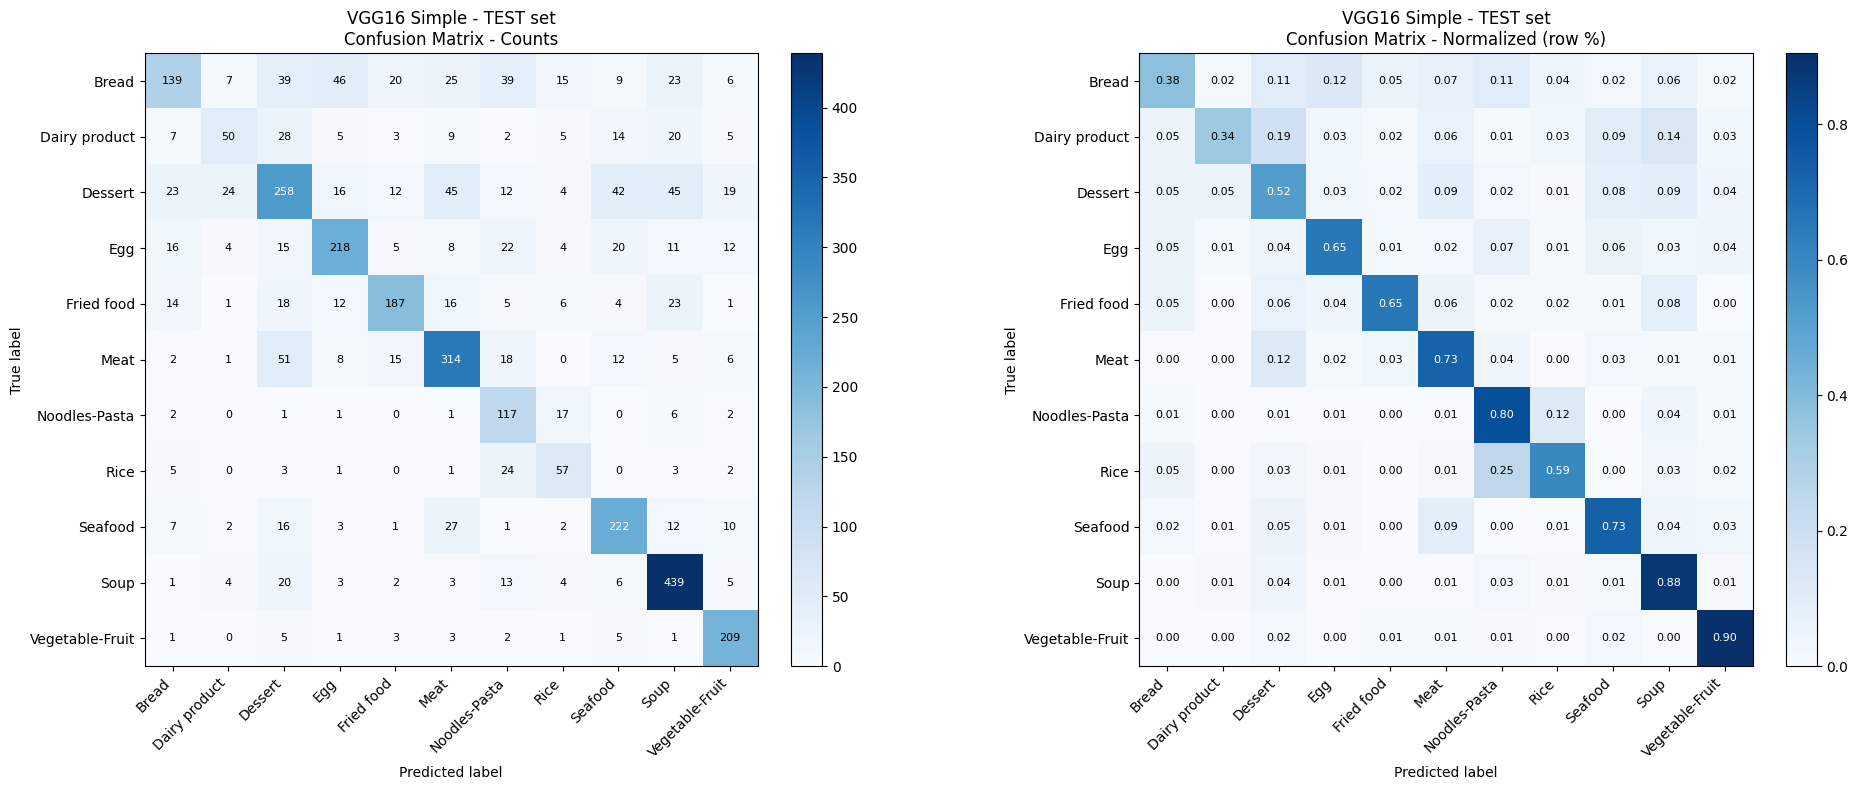

Classification Report - VGG16 Simple - TEST set
                 precision    recall  f1-score   support

          Bread      0.641     0.378     0.475       368
  Dairy product      0.538     0.338     0.415       148
        Dessert      0.568     0.516     0.541       500
            Egg      0.694     0.651     0.672       335
     Fried food      0.754     0.652     0.699       287
           Meat      0.695     0.727     0.710       432
  Noodles-Pasta      0.459     0.796     0.582       147
           Rice      0.496     0.594     0.540        96
        Seafood      0.665     0.733     0.697       303
           Soup      0.747     0.878     0.807       500
Vegetable-Fruit      0.755     0.905     0.823       231

       accuracy                          0.660      3347
      macro avg      0.637     0.651     0.633      3347
   weighted avg      0.661     0.660     0.652      3347



In [8]:
cm_simple_train, _, _ = evaluate_with_confusion(
    vgg_simple, train_eval_simple, "VGG16 Simple - TRAINING set")

cm_simple_val, _, _ = evaluate_with_confusion(
    vgg_simple, val_simple, "VGG16 Simple - VALIDATION set")

cm_simple, y_true, y_pred_simple = evaluate_with_confusion(
    vgg_simple, test_simple, "VGG16 Simple - TEST set")

# Experiment 2 — VGG16 with Transfer Learning

VGG16 convolutional base with **ImageNet weights** + a new classifier head (GlobalAveragePooling → Dense(512) → Dropout → softmax).

* **Phase 1 – Feature extraction:** base frozen, only the head is trained (learning rate 1e-3).
* **Phase 2 – Fine-tuning:** `block5` conv layers are unfrozen and trained with a very small learning rate (1e-5) so the pretrained features are adapted gently without being destroyed. The model is re-compiled after changing `trainable`.

In [9]:
import os

# If Kaggle internet is OFF, downloading ImageNet weights fails with a DNS error.
# FIX: turn Internet ON in Kaggle Notebook Settings (right sidebar -> Settings ->
# Internet -> On; requires a phone-verified Kaggle account), then restart and
# re-run from the top. As a fallback (if Internet cannot be enabled), attach a
# Kaggle dataset containing the VGG16 ImageNet weights (click "+ Add Data",
# search "vgg16", e.g. "keras-pretrained-models") and point the path below at
# the exact .h5 file Kaggle mounts it at.
LOCAL_VGG16_WEIGHTS = "/kaggle/input/keras-pretrained-models/vgg16_weights_tf_dim_ordering_tf_kernels_notop.h5"

def build_vgg16_transfer():
    if os.path.exists(LOCAL_VGG16_WEIGHTS):
        base = VGG16(weights=LOCAL_VGG16_WEIGHTS, include_top=False, input_shape=(*IMG_SIZE, 3))
    else:
        try:
            base = VGG16(weights="imagenet", include_top=False, input_shape=(*IMG_SIZE, 3))
        except Exception as e:
            raise RuntimeError(
                "Could not download ImageNet weights, and no local weights file was found at "
                f"{LOCAL_VGG16_WEIGHTS}. Either turn Internet ON in Kaggle Settings (requires a "
                "phone-verified account), or attach a Kaggle dataset with the VGG16 .h5 weights "
                "and update LOCAL_VGG16_WEIGHTS above. Original error: " + str(e))
    base.trainable = False

    inp = layers.Input(shape=(*IMG_SIZE, 3))
    x = base(inp, training=False)          # keep base in inference mode
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dense(512, activation="relu", kernel_initializer=INIT)(x)
    x = layers.Dropout(0.5)(x)
    out = layers.Dense(NUM_CLASSES, activation="softmax")(x)
    return models.Model(inp, out, name="VGG16_Transfer"), base


vgg_tl, vgg_base = build_vgg16_transfer()
vgg_tl.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=LR_TL_HEAD),
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)
vgg_tl.summary()
print("Trainable weights (phase 1):", len(vgg_tl.trainable_weights))


58889256/58889256 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "VGG16_Transfer"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_2 (InputLayer)      │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ vgg16 (Functional)              │ (None, 5, 5, 512)      │    14,714,688 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 512)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 512)            │       262,656 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 11)             │         5,643 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 14,982,987 (57.16 MB)

 Trainable params: 268,299 (1.02 MB)

 Non-trainable params: 14,714,688 (56.13 MB)

Trainable weights (phase 1): 4


### Phase 1 — train the new head (base frozen)

In [10]:
early_stopping_tl1 = EarlyStopping(monitor="val_loss", patience=4,
                                   restore_best_weights=True, verbose=1)

history_tl_head = vgg_tl.fit(
    train_tl,
    epochs=EPOCHS_TL_HEAD,
    validation_data=val_tl,
    callbacks=[early_stopping_tl1]
)

Epoch 1/10
309/309 ━━━━━━━━━━━━━━━━━━━━ 105s 331ms/step - accuracy: 0.5334 - loss: 2.9648 - val_accuracy: 0.7134 - val_loss: 0.9542
Epoch 2/10
309/309 ━━━━━━━━━━━━━━━━━━━━ 99s 321ms/step - accuracy: 0.6554 - loss: 1.0751 - val_accuracy: 0.7382 - val_loss: 0.8403
Epoch 3/10
309/309 ━━━━━━━━━━━━━━━━━━━━ 99s 321ms/step - accuracy: 0.7115 - loss: 0.9051 - val_accuracy: 0.7615 - val_loss: 0.7966
Epoch 4/10
309/309 ━━━━━━━━━━━━━━━━━━━━ 100s 322ms/step - accuracy: 0.7337 - loss: 0.8118 - val_accuracy: 0.7706 - val_loss: 0.7529
Epoch 5/10
309/309 ━━━━━━━━━━━━━━━━━━━━ 100s 323ms/step - accuracy: 0.7509 - loss: 0.7565 - val_accuracy: 0.7840 - val_loss: 0.7026
Epoch 6/10
309/309 ━━━━━━━━━━━━━━━━━━━━ 99s 321ms/step - accuracy: 0.7675 - loss: 0.6993 - val_accuracy: 0.7880 - val_loss: 0.7306
Epoch 7/10
309/309 ━━━━━━━━━━━━━━━━━━━━ 99s 322ms/step - accuracy: 0.7750 - loss: 0.6655 - val_accuracy: 0.7866 - val_loss: 0.7257
Epoch 8/10
309/309 ━━━━━━━━━━━━━━━━━━━━ 99s 319ms/step - accuracy: 0.7866 - loss

### Phase 2 — fine-tune `block5` with a small learning rate

In [11]:
# Unfreeze only block5 of the VGG16 base
vgg_base.trainable = True
for layer in vgg_base.layers:
    layer.trainable = layer.name.startswith("block5")

print("Trainable layers in base:", [l.name for l in vgg_base.layers if l.trainable])

# Must re-compile after changing trainable flags
vgg_tl.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=LR_TL_FINE),
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

early_stopping_tl2 = EarlyStopping(monitor="val_loss", patience=5,
                                   restore_best_weights=True, verbose=1)
reduce_lr_tl2 = ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=2,
                                  min_lr=1e-7, verbose=1)

history_tl_fine = vgg_tl.fit(
    train_tl,
    epochs=EPOCHS_TL_FINE,
    validation_data=val_tl,
    callbacks=[early_stopping_tl2, reduce_lr_tl2]
)

Trainable layers in base: ['block5_conv1', 'block5_conv2', 'block5_conv3', 'block5_pool']
Epoch 1/15
309/309 ━━━━━━━━━━━━━━━━━━━━ 108s 337ms/step - accuracy: 0.7949 - loss: 0.6213 - val_accuracy: 0.8073 - val_loss: 0.6771 - learning_rate: 1.0000e-05
Epoch 2/15
309/309 ━━━━━━━━━━━━━━━━━━━━ 102s 330ms/step - accuracy: 0.8236 - loss: 0.5226 - val_accuracy: 0.8108 - val_loss: 0.6952 - learning_rate: 1.0000e-05
Epoch 3/15
309/309 ━━━━━━━━━━━━━━━━━━━━ 100s 323ms/step - accuracy: 0.8388 - loss: 0.4771 - val_accuracy: 0.8216 - val_loss: 0.6376 - learning_rate: 1.0000e-05
Epoch 4/15
309/309 ━━━━━━━━━━━━━━━━━━━━ 99s 320ms/step - accuracy: 0.8519 - loss: 0.4421 - val_accuracy: 0.8283 - val_loss: 0.6255 - learning_rate: 1.0000e-05
Epoch 5/15
309/309 ━━━━━━━━━━━━━━━━━━━━ 98s 317ms/step - accuracy: 0.8653 - loss: 0.4007 - val_accuracy: 0.8286 - val_loss: 0.5973 - learning_rate: 1.0000e-05
Epoch 6/15
309/309 ━━━━━━━━━━━━━━━━━━━━ 99s 319ms/step - accuracy: 0.8715 - loss: 0.3766 - val_accuracy: 0.8414 

105/105 ━━━━━━━━━━━━━━━━━━━━ 15s 140ms/step - accuracy: 0.8656 - loss: 0.4547
VGG16 Transfer Learning - Test Loss: 0.4547
VGG16 Transfer Learning - Test Accuracy: 86.56%


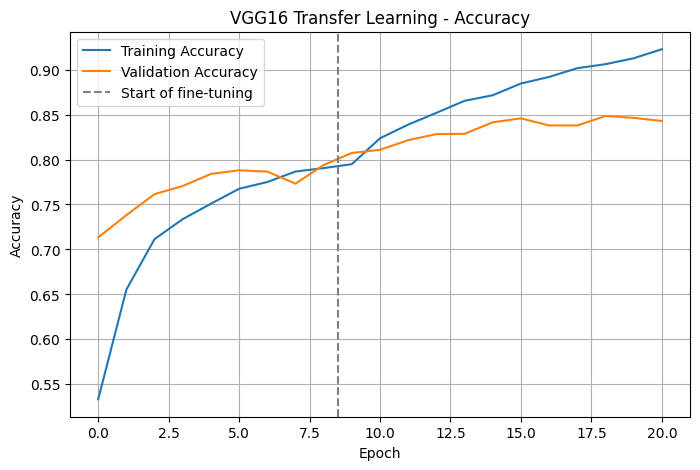

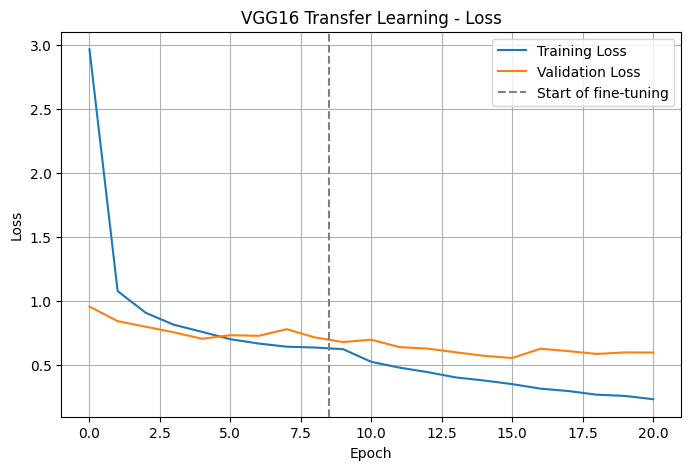

In [12]:
# Merge both phases into one history so the graphs run continuously
history_tl = {k: history_tl_head.history[k] + history_tl_fine.history[k]
              for k in history_tl_head.history if k in history_tl_fine.history}
phase_split = len(history_tl_head.history["loss"])

tl_test_loss, tl_test_acc = vgg_tl.evaluate(test_tl, verbose=1)
print(f"VGG16 Transfer Learning - Test Loss: {tl_test_loss:.4f}")
print(f"VGG16 Transfer Learning - Test Accuracy: {tl_test_acc*100:.2f}%")

plot_history(history_tl, "VGG16 Transfer Learning", phase_split=phase_split)

309/309 ━━━━━━━━━━━━━━━━━━━━ 41s 130ms/step


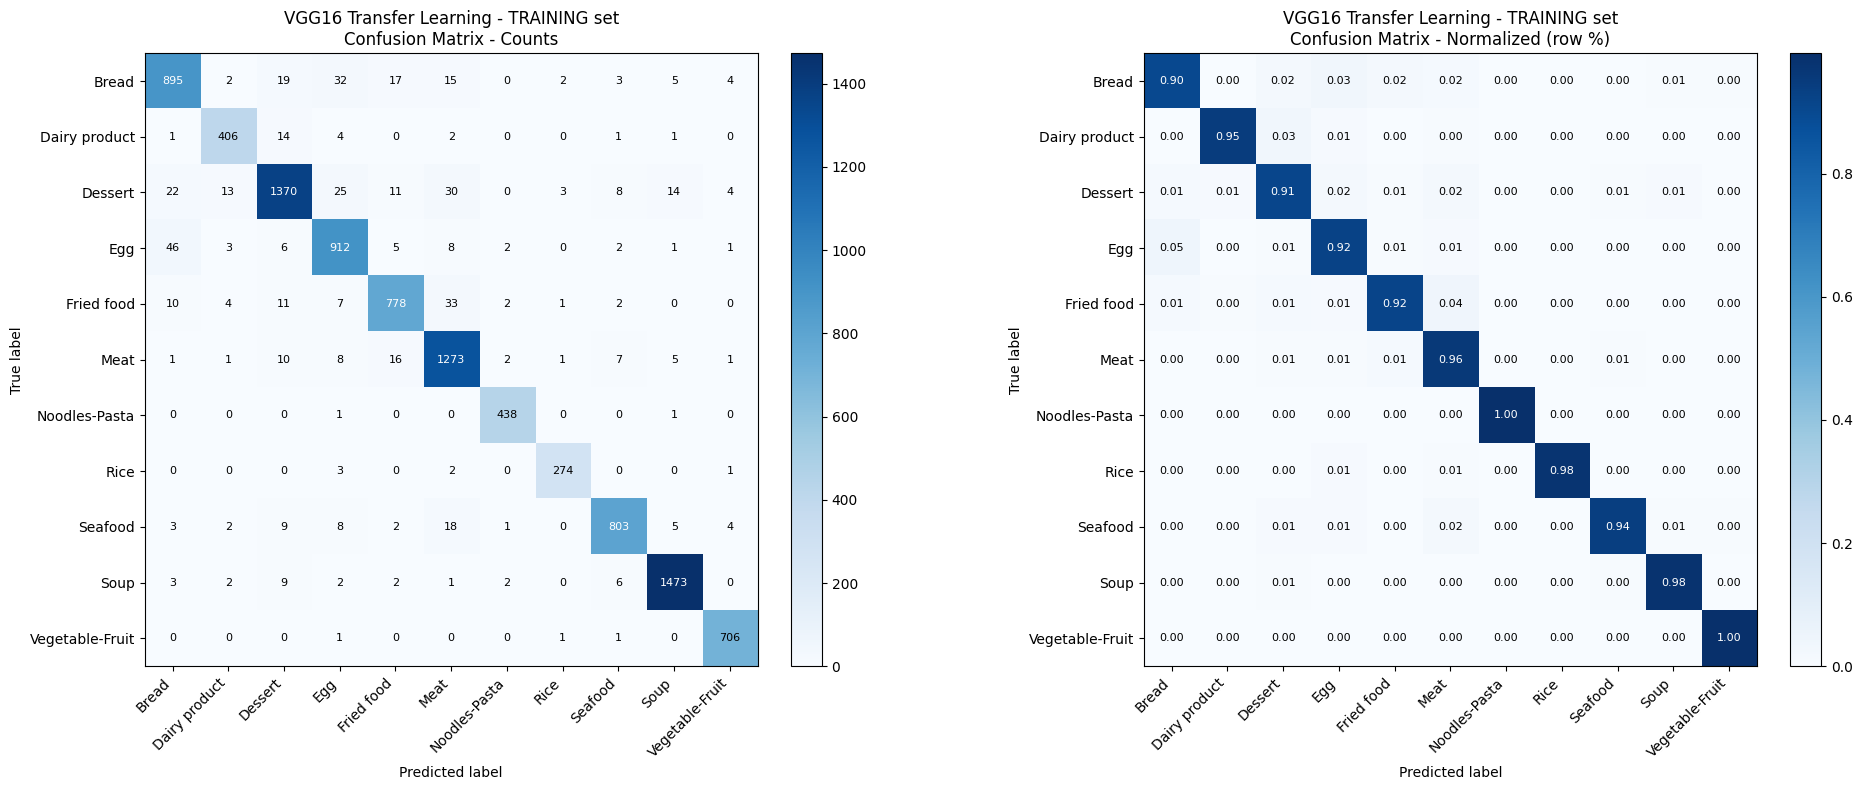

Classification Report - VGG16 Transfer Learning - TRAINING set
                 precision    recall  f1-score   support

          Bread      0.912     0.900     0.906       994
  Dairy product      0.938     0.946     0.942       429
        Dessert      0.946     0.913     0.929      1500
            Egg      0.909     0.925     0.917       986
     Fried food      0.936     0.917     0.927       848
           Meat      0.921     0.961     0.941      1325
  Noodles-Pasta      0.980     0.995     0.988       440
           Rice      0.972     0.979     0.975       280
        Seafood      0.964     0.939     0.951       855
           Soup      0.979     0.982     0.980      1500
Vegetable-Fruit      0.979     0.996     0.987       709

       accuracy                          0.945      9866
      macro avg      0.949     0.950     0.949      9866
   weighted avg      0.946     0.945     0.945      9866

108/108 ━━━━━━━━━━━━━━━━━━━━ 15s 140ms/step


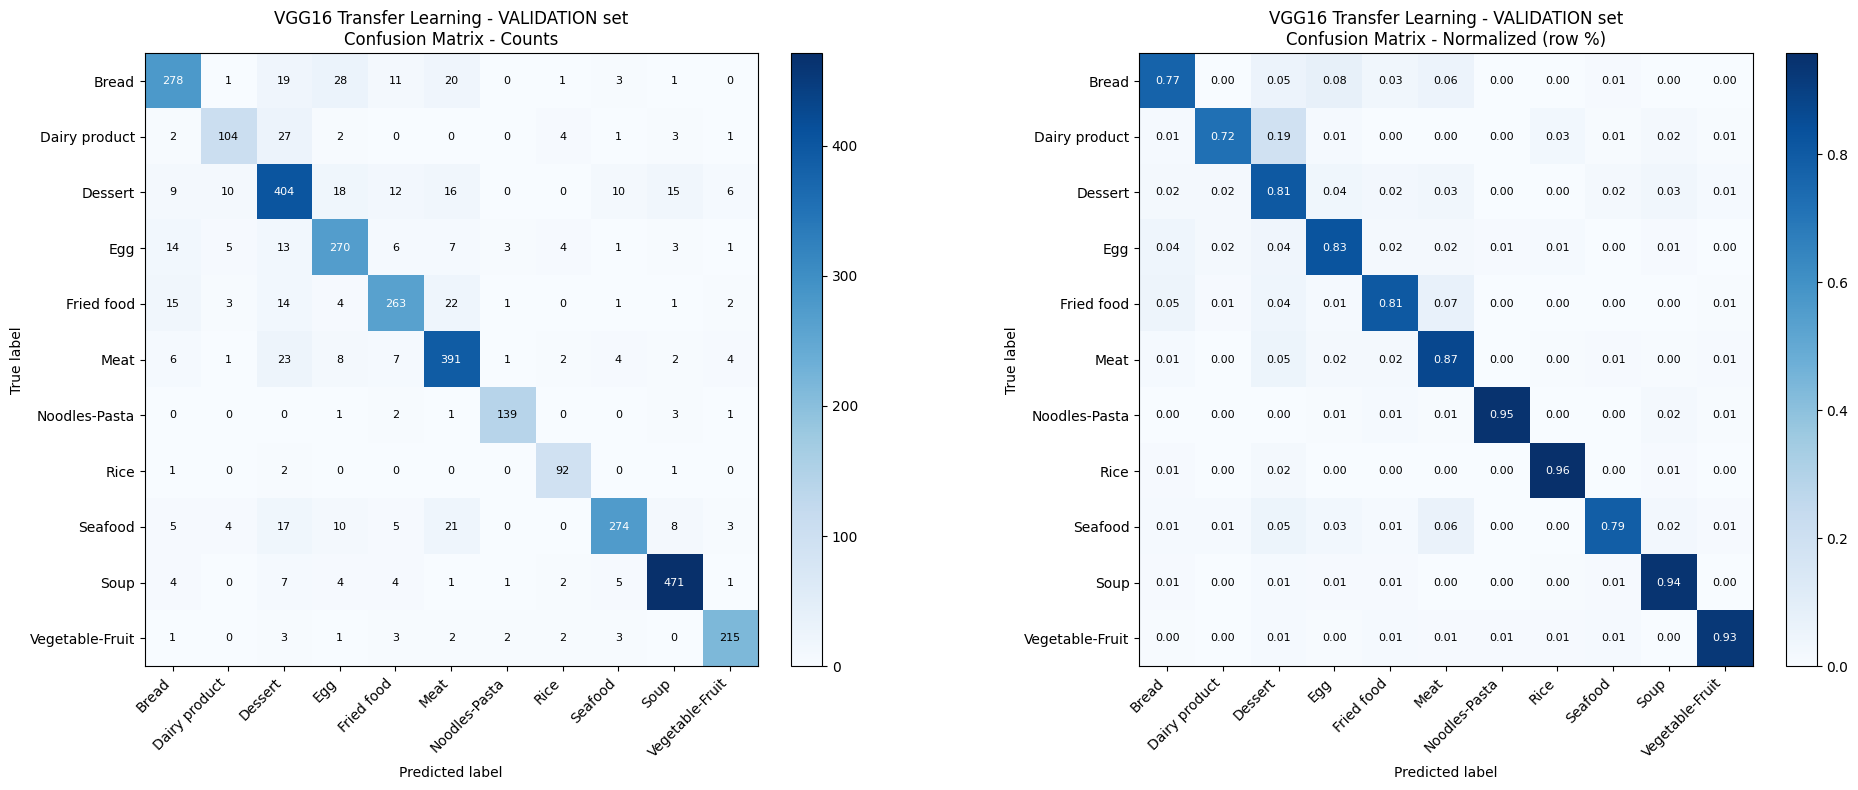

Classification Report - VGG16 Transfer Learning - VALIDATION set
                 precision    recall  f1-score   support

          Bread      0.830     0.768     0.798       362
  Dairy product      0.812     0.722     0.765       144
        Dessert      0.764     0.808     0.785       500
            Egg      0.780     0.826     0.802       327
     Fried food      0.840     0.807     0.823       326
           Meat      0.813     0.871     0.841       449
  Noodles-Pasta      0.946     0.946     0.946       147
           Rice      0.860     0.958     0.906        96
        Seafood      0.907     0.790     0.844       347
           Soup      0.927     0.942     0.935       500
Vegetable-Fruit      0.919     0.927     0.923       232

       accuracy                          0.846      3430
      macro avg      0.854     0.851     0.852      3430
   weighted avg      0.847     0.846     0.846      3430

105/105 ━━━━━━━━━━━━━━━━━━━━ 14s 136ms/step


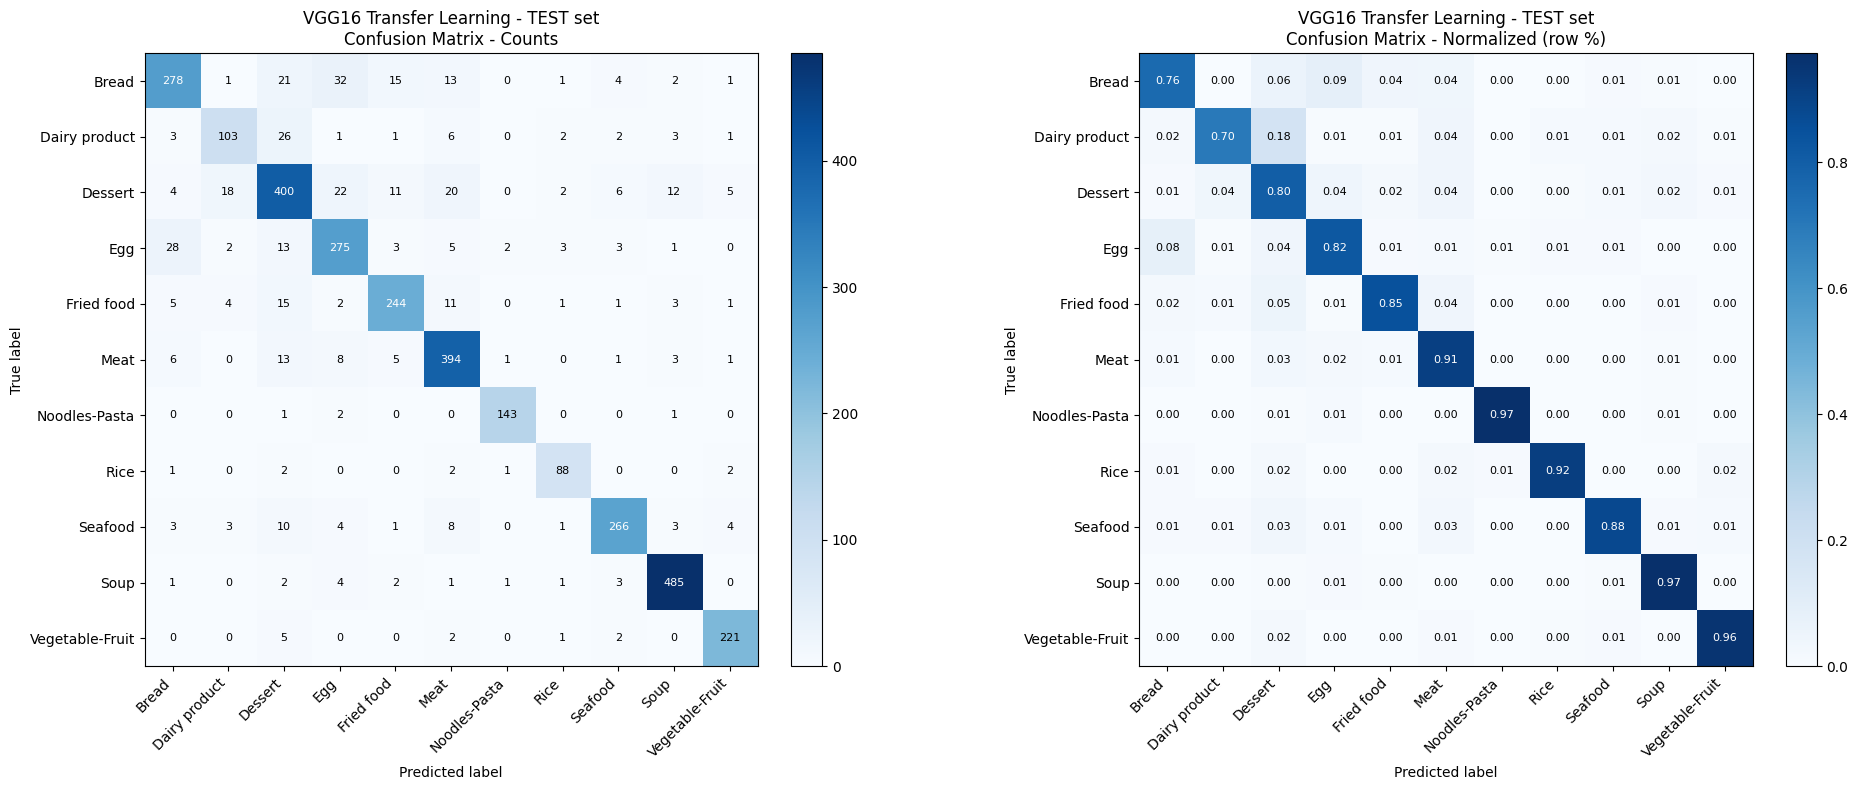

Classification Report - VGG16 Transfer Learning - TEST set
                 precision    recall  f1-score   support

          Bread      0.845     0.755     0.798       368
  Dairy product      0.786     0.696     0.738       148
        Dessert      0.787     0.800     0.794       500
            Egg      0.786     0.821     0.803       335
     Fried food      0.865     0.850     0.858       287
           Meat      0.853     0.912     0.881       432
  Noodles-Pasta      0.966     0.973     0.969       147
           Rice      0.880     0.917     0.898        96
        Seafood      0.924     0.878     0.900       303
           Soup      0.945     0.970     0.958       500
Vegetable-Fruit      0.936     0.957     0.946       231

       accuracy                          0.866      3347
      macro avg      0.870     0.866     0.868      3347
   weighted avg      0.865     0.866     0.865      3347



In [13]:
cm_tl_train, _, _ = evaluate_with_confusion(
    vgg_tl, train_eval_tl, "VGG16 Transfer Learning - TRAINING set")

cm_tl_val, _, _ = evaluate_with_confusion(
    vgg_tl, val_tl, "VGG16 Transfer Learning - VALIDATION set")

cm_tl, _, y_pred_tl = evaluate_with_confusion(
    vgg_tl, test_tl, "VGG16 Transfer Learning - TEST set")

# Final Comparison

All values below are measured from the runs above (nothing is hard-coded).

In [14]:
hist_simple = history_simple.history

def last(h, key):
    return h[key][-1] * 100

# NOTE: with restore_best_weights=True the model ends on its best epoch, so we also
# report the best-epoch validation accuracy, which matches the evaluated weights.
results = pd.DataFrame([
    ["VGG16", "Simple (from scratch)",
     last(hist_simple, "accuracy"), last(hist_simple, "val_accuracy"),
     max(hist_simple["val_accuracy"]) * 100, simple_test_acc * 100],
    ["VGG16", "Transfer Learning",
     last(history_tl, "accuracy"), last(history_tl, "val_accuracy"),
     max(history_tl["val_accuracy"]) * 100, tl_test_acc * 100],
], columns=["Model", "Technique",
            "Final Training Accuracy (%)", "Final Validation Accuracy (%)",
            "Best Validation Accuracy (%)", "Test Accuracy (%)"])

display(results.round(2))

,Model,Technique,Final Training Accuracy (%),Final Validation Accuracy (%),Best Validation Accuracy (%),Test Accuracy (%)
0,VGG16,Simple (from scratch),91.22,67.93,68.57,66.03
1,VGG16,Transfer Learning,92.27,84.29,84.84,86.56


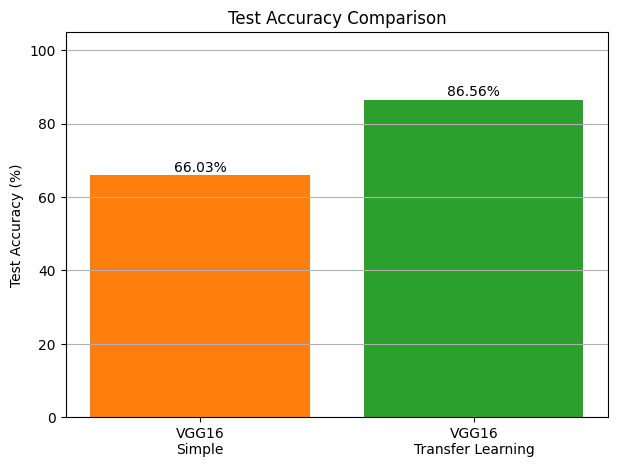

In [15]:
plt.figure(figsize=(7, 5))
labels = ["VGG16\nSimple", "VGG16\nTransfer Learning"]
bars = plt.bar(labels, results["Test Accuracy (%)"].values, color=["tab:orange", "tab:green"])
for b, v in zip(bars, results["Test Accuracy (%)"].values):
    plt.text(b.get_x() + b.get_width()/2, v + 1, f"{v:.2f}%", ha="center")
plt.ylabel("Test Accuracy (%)")
plt.title("Test Accuracy Comparison")
plt.ylim(0, 105)
plt.grid(axis="y")
plt.show()

## Combined training curves (both models)

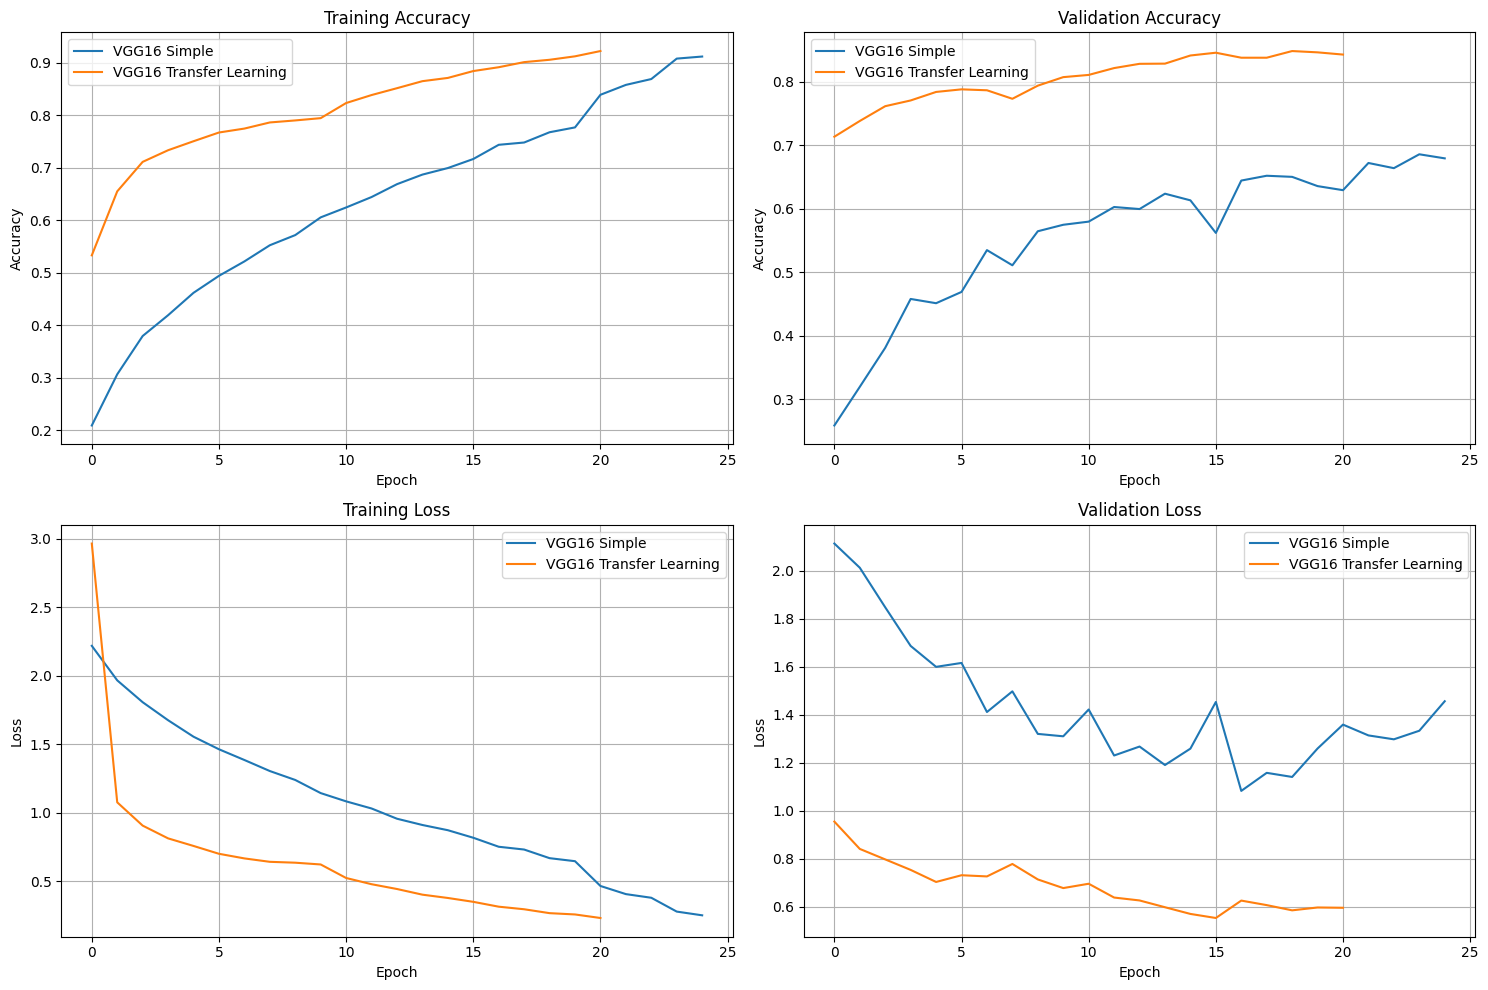

In [16]:
histories = {
    "VGG16 Simple": hist_simple,
    "VGG16 Transfer Learning": history_tl,
}

fig, axes = plt.subplots(2, 2, figsize=(15, 10))
for name, h in histories.items():
    axes[0, 0].plot(h["accuracy"], label=name)
    axes[0, 1].plot(h["val_accuracy"], label=name)
    axes[1, 0].plot(h["loss"], label=name)
    axes[1, 1].plot(h["val_loss"], label=name)

titles = ["Training Accuracy", "Validation Accuracy", "Training Loss", "Validation Loss"]
for ax, t in zip(axes.flatten(), titles):
    ax.set_title(t)
    ax.set_xlabel("Epoch")
    ax.set_ylabel(t.split()[-1])
    ax.grid(True)
    ax.legend()
plt.tight_layout()
plt.show()

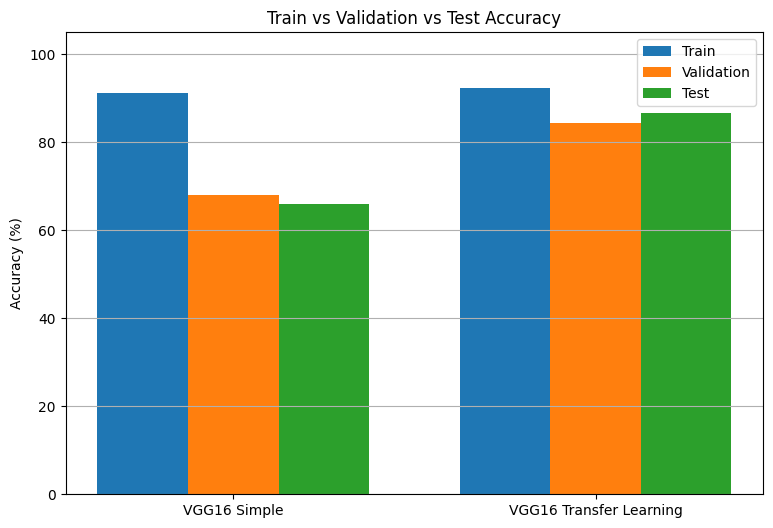

In [17]:
x = np.arange(len(results))
width = 0.25
plt.figure(figsize=(9, 6))
plt.bar(x - width, results["Final Training Accuracy (%)"], width, label="Train")
plt.bar(x, results["Final Validation Accuracy (%)"], width, label="Validation")
plt.bar(x + width, results["Test Accuracy (%)"], width, label="Test")
plt.xticks(x, ["VGG16 Simple", "VGG16 Transfer Learning"])
plt.ylabel("Accuracy (%)")
plt.title("Train vs Validation vs Test Accuracy")
plt.ylim(0, 105)
plt.legend()
plt.grid(axis="y")
plt.show()

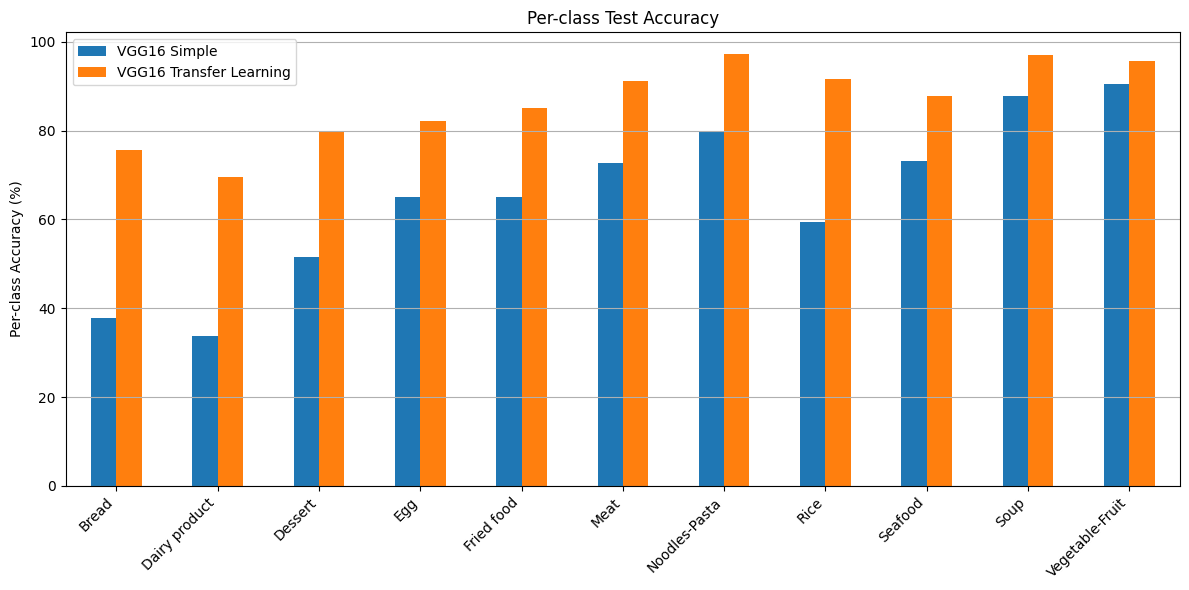

,VGG16 Simple,VGG16 Transfer Learning
Bread,37.8,75.5
Dairy product,33.8,69.6
Dessert,51.6,80.0
Egg,65.1,82.1
Fried food,65.2,85.0
Meat,72.7,91.2
Noodles-Pasta,79.6,97.3
Rice,59.4,91.7
Seafood,73.3,87.8
Soup,87.8,97.0


In [18]:
class_labels = list(test_simple.class_indices.keys())
per_class = pd.DataFrame({
    "VGG16 Simple": cm_simple.diagonal() / cm_simple.sum(axis=1),
    "VGG16 Transfer Learning": cm_tl.diagonal() / cm_tl.sum(axis=1),
}, index=class_labels) * 100

per_class.plot(kind="bar", figsize=(12, 6))
plt.ylabel("Per-class Accuracy (%)")
plt.title("Per-class Test Accuracy")
plt.xticks(rotation=45, ha="right")
plt.grid(axis="y")
plt.tight_layout()
plt.show()

display(per_class.round(1))

# Conclusion

VGG16 was trained on Food-11 in two ways: from scratch (simple) and with ImageNet transfer learning (frozen-base feature extraction followed by fine-tuning of `block5`).

Transfer learning starts from features already learned on ImageNet's 1.2M images, so it typically converges in far fewer epochs and reaches a higher validation / test accuracy than the same architecture trained from random weights on the comparatively small Food-11 training set. The from-scratch VGG16 has ~15M convolutional parameters plus a large classifier and has to learn all features from the food images alone, so it is slower to train and more prone to overfitting (look for a widening gap between the training and validation curves).

Use the measured graphs, the confusion matrices (which food classes are confused, e.g. similar-looking dishes) and the final comparison table above to write the interpretation – the conclusion should follow the actual numbers from your run.